In [8]:
# Required imports

import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator 
from qiskit.circuit.library import CDKMRippleCarryAdder

# The CDKM Modular Exponentiator

## Overview

The CDKM Modular Exponentiator is a quantum circuit that finds the value of $a^x$ mod $N$. This notebook will build this circuit up starting from basic quantum gates. Each code block will introduce the user to the next layer up in the stack. The component circuits may therefore be run inidividually to see how they function; see below for a list of sections. As each layer builds upon the previous one, the user is advised to run the whole notebook before experimenting.  

### Sections

- **MAJORITY and UNMAJORITY Gates**
- **The CDKM Ripple Carry Adder (from Gates)**
- **The CDKM Ripple Carry Adder (from Qiskit's Circuit Library)**
- **The CDKM Modular Adder**
- **The CDKM Modular Multiplier**
- **The CDKM Modular Exponentiator**




### Majority and Unmajority Gates

The MAJORITY gate consists of two CNOT gates and a CCNOT (Toffoli) gate and requires 3 total qubits. If there are more qubits in the state $\ket{0}$ it outputs 0, and if there are more qubits in the state $\ket{1}$ it outputs 1. In other words it determines if the majority of the qubits are in the state $\ket{0}$ or $\ket{1}$, hence the name. In terms of addition, this gate finds the carry (i.e. carry the 1).

The UNAMJORITY gate simultaneously undoes the carry calculation of the previous gate and computes the sum. We will see in the next section how these gates work together to perform addition. Both gates implemented below.

The MAJORITY Gate:


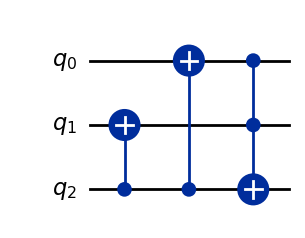

The UNMAJORITY Gate:


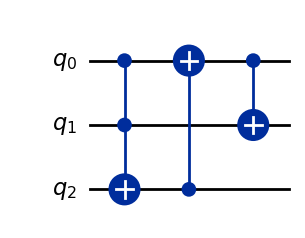

In [9]:

def MAJ_GATE(show = False):
    """Creates a MAJORITY Gate"""

    # Create the circuit
    qc = QuantumCircuit(3, name="MAJ")
    qc.cx(2, 1)
    qc.cx(2, 0)
    qc.ccx(0, 1, 2)

    # Send created circuit to instruction for later use
    maj_gate = qc.to_instruction()
    
    if (show == True):
        display(qc.draw("mpl"))

    return maj_gate


def UMA_GATE(show = False):
    """Creates an UNMAJORITY Gate"""

    # Create the circuit
    qc = QuantumCircuit(3, name="UMA")
    qc.ccx(0, 1, 2)
    qc.cx(2, 0)
    qc.cx(0, 1)

    # Send the created circuit to instruction for later and find results
    uma_gate = qc.to_instruction()
    
    if (show == True):
        display(qc.draw("mpl"))

    return uma_gate

print("The MAJORITY Gate:")
maj_gate = MAJ_GATE(True)

print("The UNMAJORITY Gate:")
uma_gate = UMA_GATE(True)



### The CDKM Ripple Carry Adder (from Gates)

The goal of this circuit is to find the sum of two integers a and b. The process is as follows: 

1. Each integer is written in its binary form as a = $a_{n-1}a_{n-2}...a_{1}a_{0}$, where $a_{i}$ corresponds to $a_{i} \cdot 2^{i}$ in decimal notation (so that $a = \sum_{i=0}^{n-1} a_{i} 2^{i}$).

2. A sequence of MAJORITY gates calculates the carry for each digit of the binary representation. For example, if $a_{0} = 1$ and $b_{0} = 1$, then $a_{0} + b_{0} = 0$ with 1 as the carry. This is checked for each digit in turn. 

3. If the last digit requires a carry, a CNOT gate stores this on the acilla qubit to prevent overflow.

4. The UNMAJORITY gate uncomputes the carry and computes the sum. In this manner we are left with the carry value on the ancilla qubit and $a_{i} + b_{i}$ on what was originally the qubit containing $b_{i}$

5. We measure the ancilla and the b register (now containing a + b bitwise) and convert the result back from binary to decimal.

Thus applying the CDKM Ripple Carry Adder gate to $\ket{a}\ket{b}$ yields $\ket{a}\ket{a+b}$

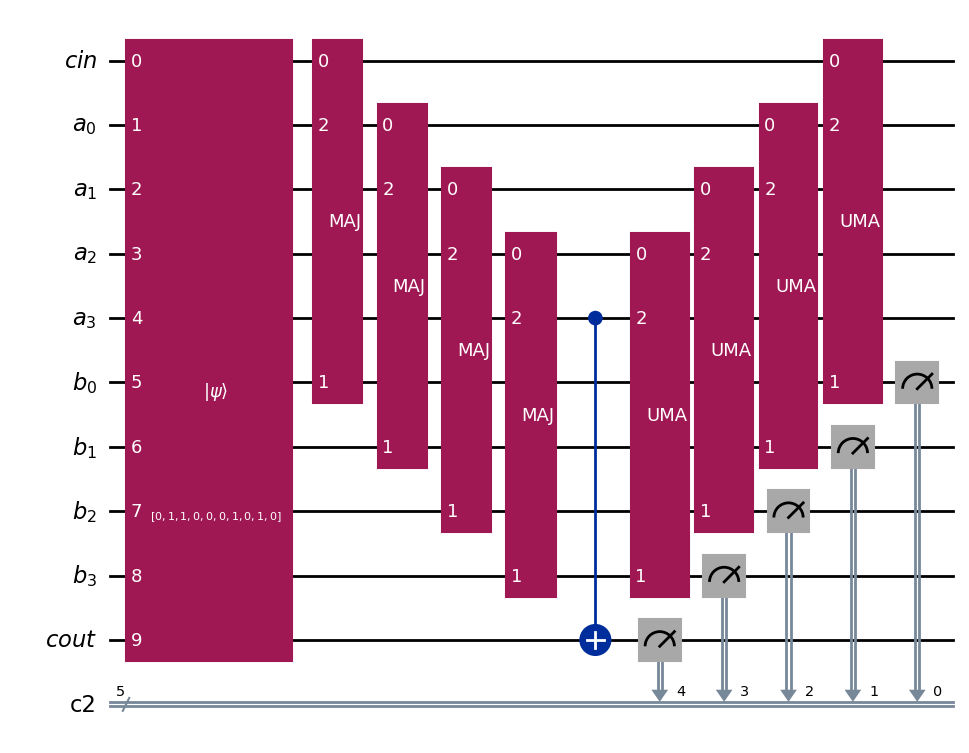

Value of a: 5
Value of b: 12
Bit length n = 4 

Expected result: 17
Integer result: 17
Correct? True 

Qubits Required for CDKM Ripple Carry Adder: 2(n + 1) = 10


In [10]:

def custom_CDKM_RIPPLE(a: int, b: int):
    """ Function to perform addition using the CDKM Ripple Carry Adder"""

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)      

    # Pad the binary if they are not the same length string
    if (length_of_a>length_of_b):
        padding = "0" * np.abs(length_of_a - length_of_b)
        b_binary = padding + np.binary_repr(b)
    elif (length_of_a<length_of_b):
        padding = "0" * np.abs(length_of_b - length_of_a)
        a_binary = padding + np.binary_repr(a)

    # Lengths of the (padded) binary representation will be used to determine gate structure and how the result is stored
    length_of_a = n = len(a_binary)
    length_of_b = len(b_binary)

    # Create the circuit
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(length_of_a, "a")
    b_register = QuantumRegister(length_of_b, "b")
    cout = QuantumRegister(1, "cout")

    # The number of classical bits needed is size of b plus 1 for the carry
    classical_bits = ClassicalRegister(length_of_b + 1)
    qc = QuantumCircuit(cin, a_register, b_register, cout, classical_bits)

    # We want to have a then b in increasing bit order
    # Read right to left that means we want a_binary first, the b_binary
    # The zeroes are because we want cin and cout to initalize to zero
    initial_state = "0" + b_binary + a_binary + "0"
    qc.initialize(initial_state, qc.qubits)

    # The number of qubits needed is cin + binary representation length + cout
    total_qubits = len(initial_state)

    # Create the gates from what we made before
    MAJ = MAJ_GATE()
    UMA = UMA_GATE()

    # Now we implement the gates constructed earlier
    b_start = length_of_a + 1
    for i in range(0, length_of_a):

        # Start with cin, b0, a0, then shift down by 1 each time
        input_a = i
        input_b = b_start + i
        input_c = i + 1

        qargs = [input_a, input_b, input_c]
        qc.append(MAJ, qargs)

    # Then we add the CNOT using the last digit of a and cout for the carry
    qc.cx(length_of_a, total_qubits-1) # minus 1 because we index starting from 0

    # Finally we implement the UMA gates
    for j in range(0, length_of_a):

        # The UMA gates "undo" the MAJ gates
        # So we invert the order of the previous inputs
        qargs = [input_a - j, input_b - j, input_c - j]
        qc.append(UMA, qargs)


    # Measure the state and get the bits
    # Little endian ordering
    binary_bits = [n+1+i for i in range(length_of_b+1)]
    classical_array = [i for i in range(n+1)]


    # Measurement of register bits yields the outcome of addition
    qc.measure(binary_bits, classical_array)

    # Show the completed circuit
    display(qc.draw("mpl"))

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    for bits in counts:
        integer_result = int(bits, 2)

    return integer_result, total_qubits, n

# Using the circuit
a = 5
b = 12

output, qubits_needed, n = custom_CDKM_RIPPLE(a, b)

print("Value of a:", a)
print("Value of b:", b)
print("Bit length n =", n, "\n")
print("Expected result:", a + b)
print("Integer result:", output)
print("Correct?", a+b == output, "\n")
print("Qubits Required for CDKM Ripple Carry Adder: 2(n + 1) =", qubits_needed)


### The CDKM Ripple Carry Adder (from Qiskit's Circuit Library)

The CDKM Ripple Carry Adder may also be called from the existing library of circuits provided by Qiskit. The implementation is similar to the example provided above. For the rest of the notebook the circuits will be built using the Qiskit implementation to provide consistency across projects.

Documentation of the Qiskit CDKM Ripple Carry Adder can be found here: https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.CDKMRippleCarryAdder

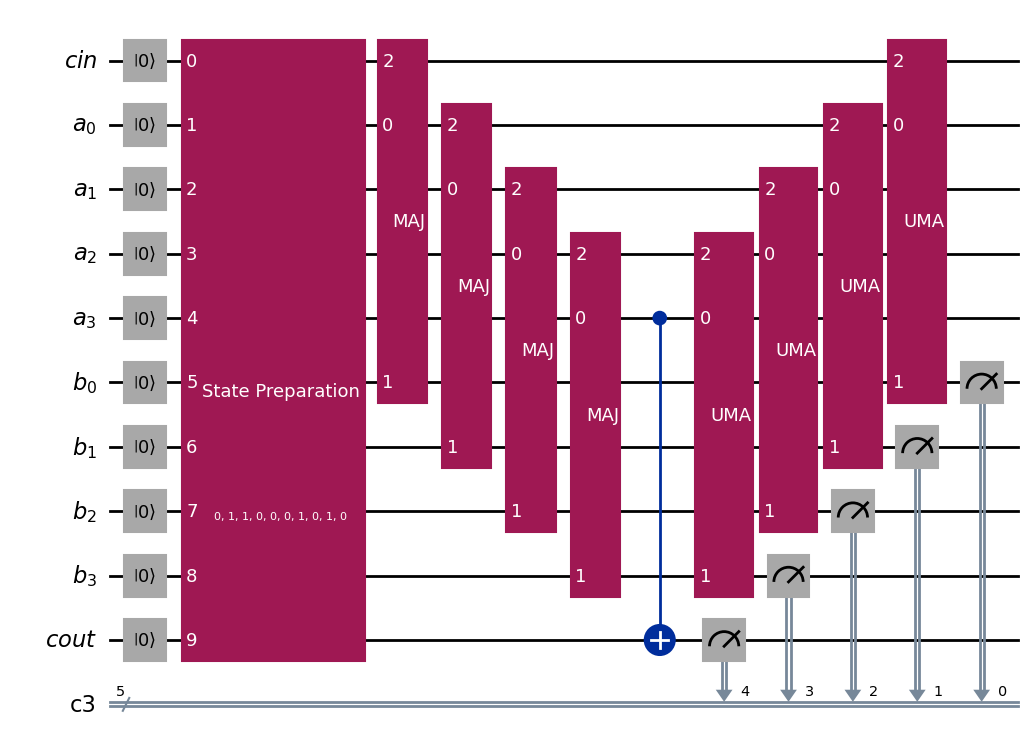

Value of a: 5
Value of b: 12
Bit length n = 4 

Expected result: 17
Integer result: 17
Correct? True 

Qubits Required for CDKM Ripple Carry Adder: 2(n + 1) = 10


In [11]:

def CDKM_RIPPLE(a: int, b: int):
    """ Function to perform addition using the CDKM Ripple Carry Adder"""

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)      

    # Pad the binary if they are not the same length string
    if (length_of_a>length_of_b):
        padding = "0" * np.abs(length_of_a - length_of_b)
        b_binary = padding + np.binary_repr(b)
    elif (length_of_a<length_of_b):
        padding = "0" * np.abs(length_of_b - length_of_a)
        a_binary = padding + np.binary_repr(a)

    # Lengths of the (padded) binary representation will be used to determine gate structure and how the result is stored
    length_of_a = n = len(a_binary)
    length_of_b = len(b_binary)

    # Create the circuit
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(length_of_a, "a")
    b_register = QuantumRegister(length_of_b, "b")
    cout = QuantumRegister(1, "cout")

    # The number of classical bits needed is size of b plus 1 for the carry
    classical_bits = ClassicalRegister(length_of_b + 1)
    qc = QuantumCircuit(cin, a_register, b_register, cout, classical_bits)

    # We want to have a then b in increasing bit order
    # Read right to left that means we want a_binary first, the b_binary
    # The zeroes are because we want cin and cout to initalize to zero
    initial_state = "0" + b_binary + a_binary + "0"
    qc.initialize(initial_state, qc.qubits)

    # The number of qubits needed is cin + binary representation length + cout
    total_qubits = len(initial_state)

    # Use Qiskit's CDKM Ripple Carry Adder
    CDKM_circuit = CDKMRippleCarryAdder(n, kind="full", name="CDKM")
    circuit_with_adder = qc.compose(CDKM_circuit)

    # Measure the state and get the bits
    # Little endian ordering
    binary_bits = [n+1+i for i in range(length_of_b+1)]
    classical_array = [i for i in range(n+1)]

    # Measurement of register bits yields the outcome of addition
    circuit_with_adder.measure(binary_bits, classical_array)
    circuit_with_adder = circuit_with_adder.decompose()

    # Show the completed circuit
    display(circuit_with_adder.draw("mpl"))

    counts = sim.run(transpile(circuit_with_adder, sim), shots=10).result().get_counts()

    for bits in counts:
        integer_result = int(bits, 2)

    return integer_result, total_qubits, n

# Using the circuit
a = 5
b = 12

output, qubits_needed, n = CDKM_RIPPLE(a, b)

print("Value of a:", a)
print("Value of b:", b)
print("Bit length n =", n, "\n")
print("Expected result:", a + b)
print("Integer result:", output)
print("Correct?", a+b == output, "\n")
print("Qubits Required for CDKM Ripple Carry Adder: 2(n + 1) =", qubits_needed)


### The CDKM Modular Adder

We now use the CDKM Ripple Carry Adder to construct a modular adder. Our goal is to find $a + b$ mod $N$ for integers $a, b, N$ with $a, b <N$


#### Explanation of Circuit

The circuit is divided into three sections. Note that the inverse of subtraction is addition, hence the inverse of the addition gate is a subtraction gate.

1. First the adder finds $a + b$, then the swap gates place N on the main register, and the inverse adder (subtraction) finds $a + b - N$

2. The behaviour of the second section changes depending on the result of $a + b - N$. If $a + b - N < 0$, then $a + b < N$. Hence we need only add $a$ and $b$ to find $a + b$ mod $N$. To do this, note that $a + b - N < 0$ means that the final digit of the register will be 1 (as a negative binary number). Thus the CNOT gate targeting the ancilla will not be activated. In turn none of the following CNOT gates will be activated either.

    This leads to a cascade of gates cancelling with their inverses: The addition gate in the second section cancels with its inverse from the first section, then the SWAP gates cancel each other (since SWAP is it's own inverse), and finally the inverse adder cancels with the inital adder. In effect, the circuit consists of a single adder gate which finds $a + b$ exactly as we wanted.

3. On the other hand, if $a + b - N \geq 0$, then $a + b \geq N$ In this case the final digit will be 0 and so the CNOT gate targeting the ancilla is activated. This results in N being temporarily removed from the first register and then put back. The swap gates then replace $a$ and $N$ back to their original registers. The subtraction gate then removes $a$ giving $b - N$, which will be negative since $b$ strictly less than $N$. As a result the final CNOT will reset the ancilla to 0. Lastly the addition gate adds $a$ again, giving us $a + b - N$.

Since $a < N$ and $b < N$, $a + b < 2N$, therfore $0 \leq a + b - N < N$. Thus we again have our desired result of $a + b$  mod $N$.


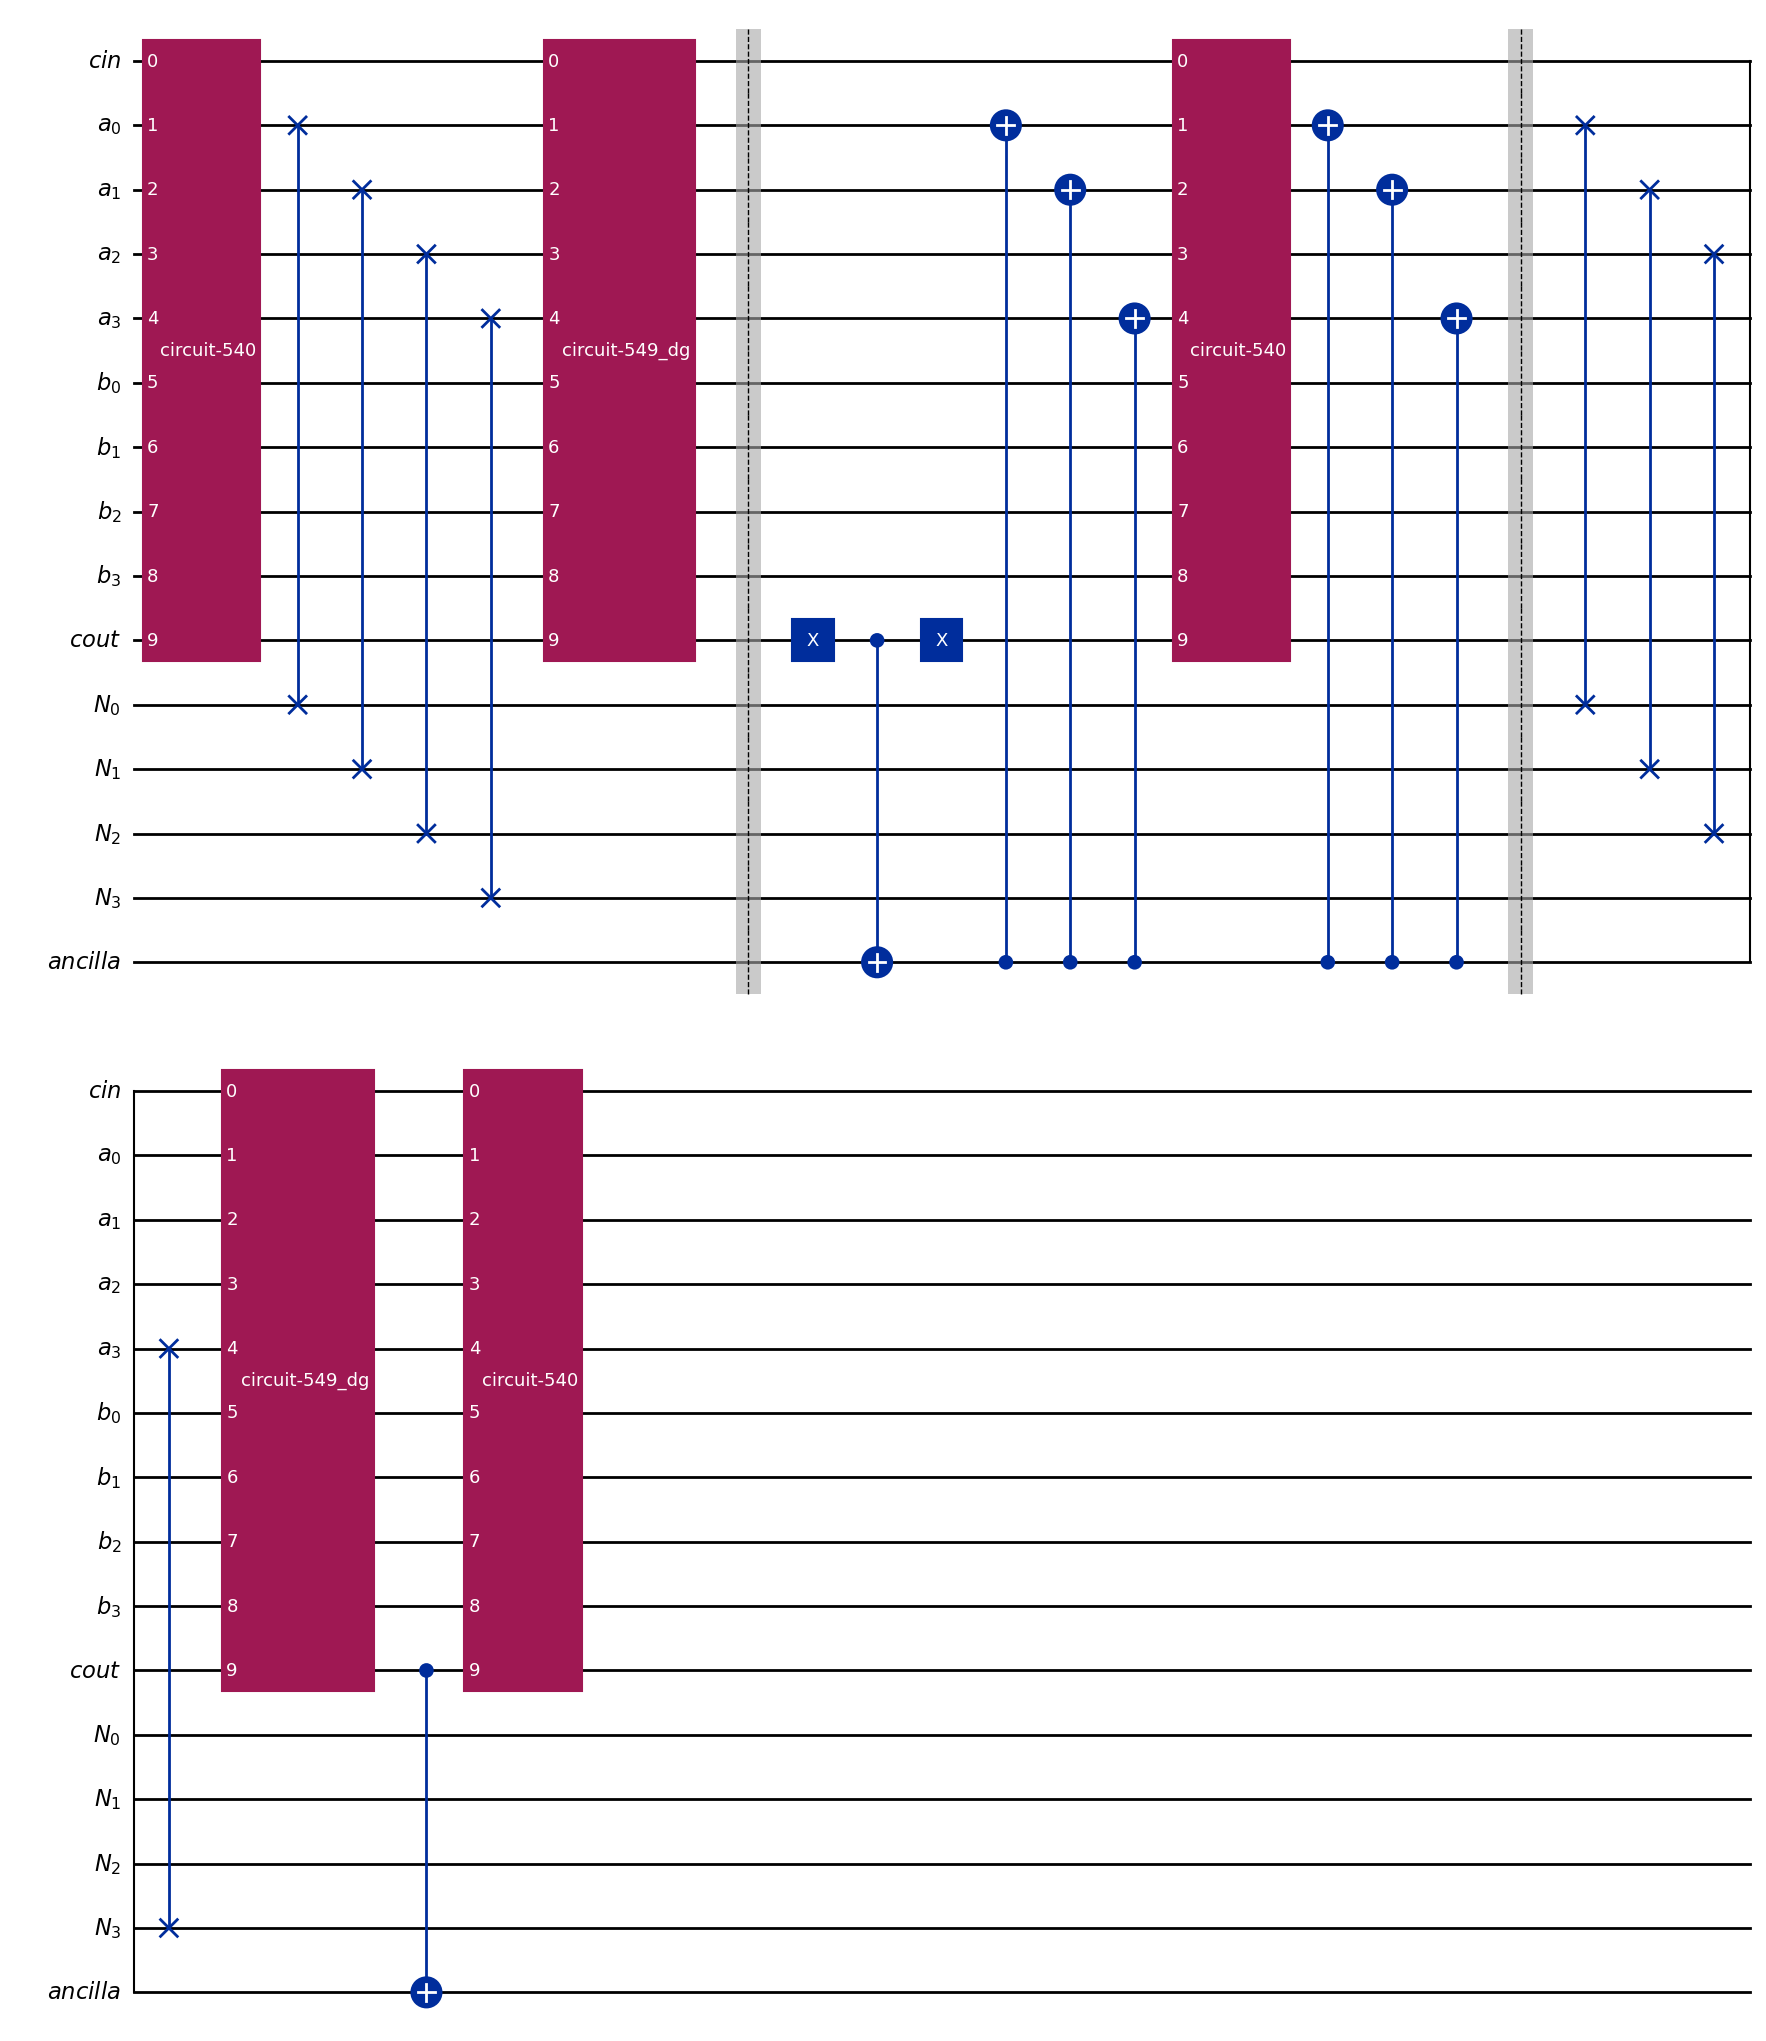

RESULT FOR CIRCUIT ABOVE

Value of a: 7
Value of b: 9
Value of N: 11

Bit length n = 4
Qubits Required for CDKM Modular Adder: 3(n + 1) = 15 

Expected result:  5
Calculated result: 5
Correct? True 

RESULT

Value of a: 5
Value of b: 12
Value of N: 17

Bit length n = 5
Qubits Required for CDKM Modular Adder: 3(n + 1) = 18 

Expected result:  0
Calculated result: 0
Correct? True 



In [12]:

def CDKM_MODDADD(N: int, showcircuit = False):
    """Function to create the CDKM-based Modular Adder"""

    N_binary = np.base_repr(N)
    n = len(N_binary)

    # Create the circuit
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    cout = QuantumRegister(1, "cout")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla")

    # The number of classical bits needed is size of b
    # classical_bits = ClassicalRegister(n)

    qc = QuantumCircuit(cin, a_register, b_register, cout, N_register, ancilla, name ="CDKM_MODADD")

    # Use Qiskit's CDKMRippleCarryAdder
    CDKM = CDKMRippleCarryAdder(n, kind="full", name="CDKM") #.decompose()
    CDKM_inverse = CDKMRippleCarryAdder(n, kind="full", name="CDKM_inv").inverse() #.decompose()

    # Establishing the bits places of each number and how they are positioned on the circuit
    # cin = 0

    first_digit_of_a = 1
    last_digit_of_a = n
    # first_digit_of_b = n + 1
    # last_digit_of_b = 2*n

    c_out = 2*n + 1

    first_digit_of_N = 2*(n+1)
    # last_digit_of_N = 3*n + 1

    ancillary = 3*n + 2

    # Step 1 is the Adder
    qc = qc.compose(CDKM)

    # Step 2 is the SWAP for a and N
    for i in range(first_digit_of_a, last_digit_of_a+1):
        # Swapping the entries along original a with those along original N
        # The -1 is to accomodate that i starts at 1 (due to the ancilla)
        qc.swap(i, first_digit_of_N + i - 1)

    # Step 3 is the inverse adder (subtraction)
    qc = qc.compose(CDKM_inverse)

    if (showcircuit == True):
        qc.barrier()

    # Step 4 is the 0-control output to flip the ancilla qubit if needed
    qc.x(c_out)
    qc.cx(c_out, ancillary)
    qc.x(c_out)

    # Step 5 is the cancellation of N if the ancilla is 1
    # We need to know which registers started in 1 so we can apply the cx gate
    N_digits_list = list(N_binary)
    N_digits_list.reverse() # reverse because the indicies start from the right

    for index, value in enumerate(N_digits_list):
        # if there's a 1 we need to flip that index so that at the end all are 0
        if (value == "1"):
            qc.cx(ancillary, index + 1) # controlled by ancillary, flip the register where the "1" is

    # Step 6 is the Add gate again
    qc = qc.compose(CDKM)

    # Step 7 we replace N on the initial register (if it was cancelled before)
    for index, value in enumerate(N_digits_list):
        # if there's a 1 we need to re-flip that index
        if (value == "1"):
            qc.cx(ancillary, index + 1) # controlled by ancillary, flip the register where the "1" is

    if (showcircuit == True):
        qc.barrier()

    # Step 8 we swap the registers back to what they were at the start
    for i in range(first_digit_of_a, last_digit_of_a+1):
        # Swapping the entries along original a with those along original N
        # The -1 is to accomodate that i starts at 1 (due to the ancilla)
        qc.swap(i, first_digit_of_N + i - 1)


    # Step 9 we subtract again
    qc = qc.compose(CDKM_inverse)

    # Step 10, reset the ancillary
    qc.cx(c_out, ancillary)

    # Step 11 add N again
    qc = qc.compose(CDKM)

    # Send the circuit to instruction for later use
    cdkm_modadd = qc.to_instruction()

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return cdkm_modadd


def create_cdkm_modadd_circuit(a: int, b: int, N: int, showcircuit = False):
    """Prepares a circuit and finds the result of a + b mod N using the CDKMRippleCarryAdder"""

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    N_binary = np.binary_repr(N)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)
    length_of_N = len(N_binary)      

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_a < length_of_N):
        padding = "0" * (length_of_N - length_of_a)
        a_binary = padding + a_binary
    if (length_of_b < length_of_N):
        padding = "0" * (length_of_N - length_of_b)
        b_binary = padding + b_binary

    length_of_a = len(a_binary)
    length_of_b = len(b_binary) # Now equal to length of N_binary for consitency

    initial_state = "0" + N_binary + "0" + b_binary + a_binary + "0"


    qubits_needed = len(initial_state)
    classical_bits_needed = len(b_binary) # Output is on the register where b started

    # Create the quantum circuit
    qc = QuantumCircuit(qubits_needed, classical_bits_needed)

    # Initialize the circuit
    qc.initialize(initial_state, qc.qubits)

    n = len(a_binary)

    # Use the circuit that we created above to find the result
    my_cdkm_modadd = CDKM_MODDADD(N, showcircuit)

    qc = qc.compose(my_cdkm_modadd, qc.qubits)

    # Get the result from the register where it is stored
    binary_bits = list(range(n + 1, 2*n + 1))
    classical_bits = list(range(classical_bits_needed))

    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()
    # print(counts)

    # Show results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of b:", b)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for CDKM Modular Adder: 3(n + 1) = {qubits_needed} \n")

        expected = np.mod(a+b, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")

# Use the circuit
a = 7
b = 9
N = 11

create_cdkm_modadd_circuit(a, b, N, showcircuit=True)

create_cdkm_modadd_circuit(5, 12, 17)


### The CDKM Modular Multiplier

The Modular Multiplier works by breaking multiplication down into a series of additions. The goal is to calculate $ax$ mod $N$.
We define the modular exponentiator circuit in the final section.

The binary representation of the number $x$ is given as $x_{n-1} \ x_{n-2} \ \dots \ x_1 \ x_0$.
The expansion of $x$ in base 2 is:
$$x = x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})$$

When we multiply $x$ by a scalar `a`, the equation is:
$$ax = x_0(a \cdot 2^0) + x_1(a \cdot 2^1) + \dots + x_{n-2}(a \cdot 2^{n-2}) + x_{n-1}(a \cdot 2^{n-1})$$

We want to calculate $ax$ mod $N$. This is equivalent to the sum (mod $N$) of the terms $x_i(a2^i)$ for all digits $x_i$ which are set to $1$ in binary. Let $C_i = a2^i$. To find the desired sum, we use gates controlled by the binary digits of x to put $C_i$ on the addition register. If $x_i = 1$, $C_i$ is added using the Modular Adder from the previous section to ensure the sum remains mod $N$. Repeating this process across all digits of x results in $ax$ mod $N$.

The circuit also includes an overall control register. If not activated, this register will set the result to the binary value of $x$ itself. This feature is useful for the next section when we must use several controlled Modular Multiplier gates to create the Modular Exponentiator.





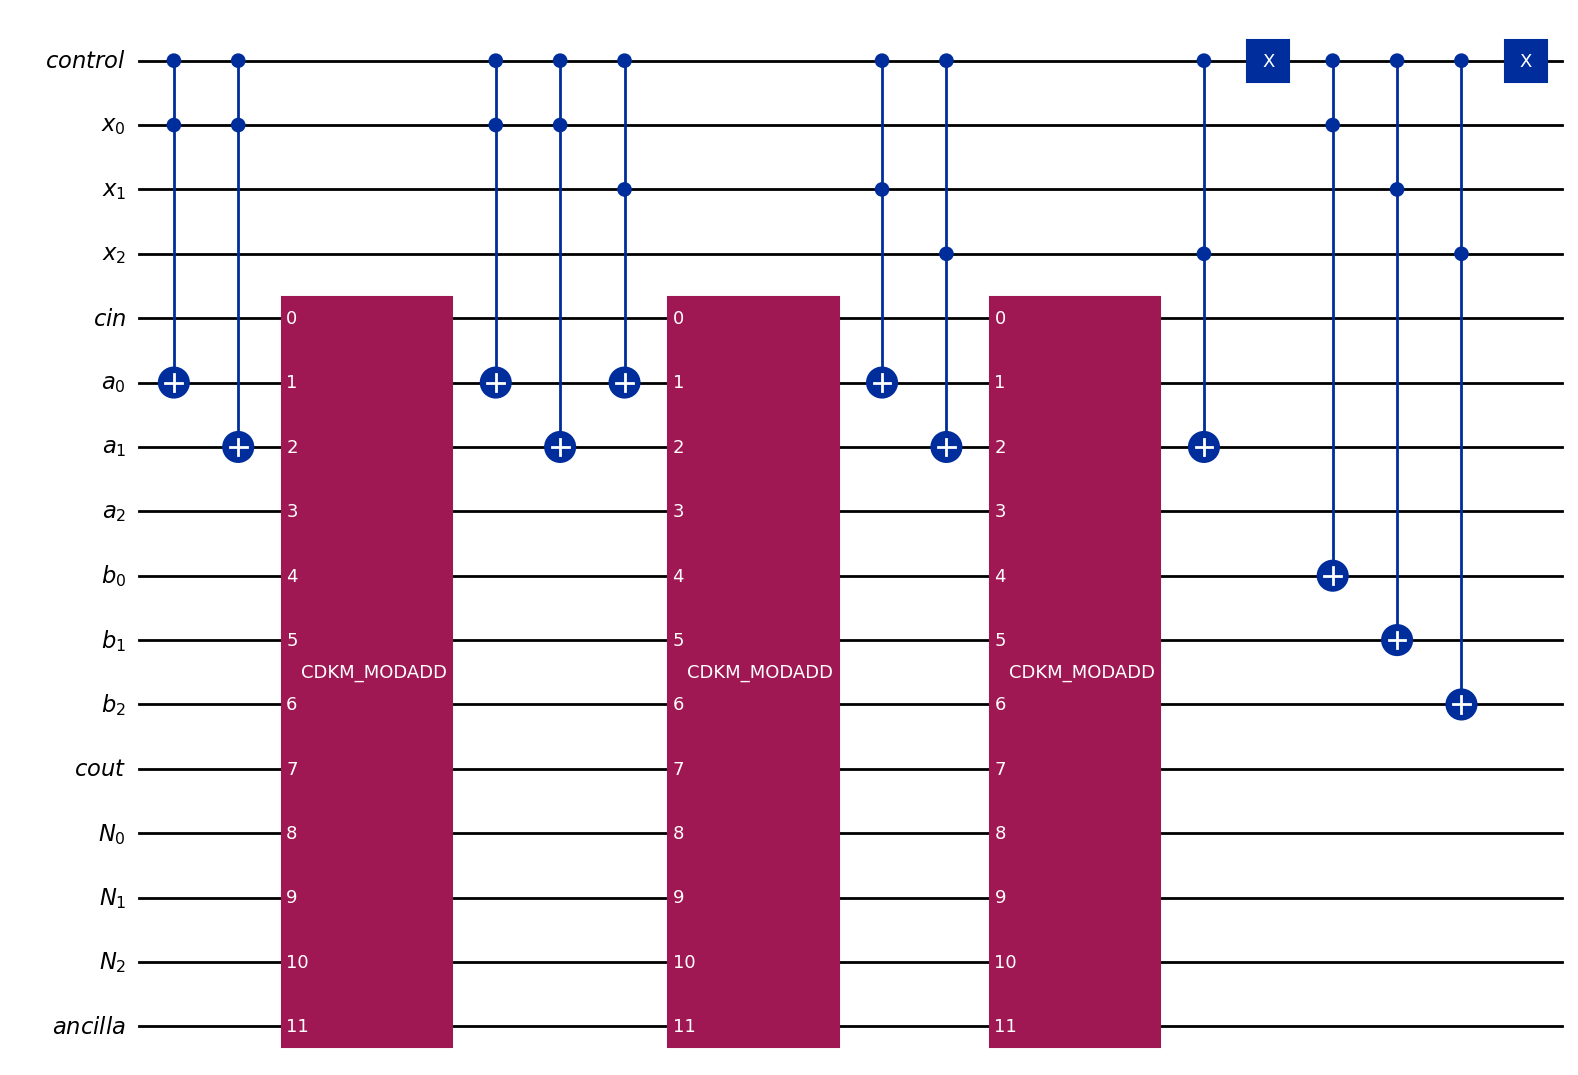

RESULT FOR CIRCUIT ABOVE

Value of a: 3
Value of b: 9
Value of N: 5

Bit length n = 3
Qubits Required for CDKM Modular Multiplier: 4(n + 1) = 16 

Expected result:  1
Calculated result: 1
Correct? True 

RESULT

Value of a: 7
Value of b: 9
Value of N: 15

Bit length n = 4
Qubits Required for CDKM Modular Multiplier: 4(n + 1) = 20 

Expected result:  6
Calculated result: 6
Correct? True 



In [ ]:


def CDKM_MODMULT(a: int, N: int, showcircuit = False):
    """Function to create the Modular Multiplier Gate using the CDKM Modular Adder"""

    N_binary = np.binary_repr(N)
    n = len(N_binary)

    # Finding the constants to pass to the circuit
    constants_array = [0*k for k in range(n)] # init empty array of correct size.

    # Calcualtion of each Ci
    for i in range(n):

        # In one step we calculate a(2^i) mod N
        constant_modded = np.mod(a*(2**i), N)
        constant_binary = np.binary_repr(constant_modded)
        constants_array[i] = constant_binary


    # Create the circuit
    control = QuantumRegister(1, "control")
    x_register = QuantumRegister(n, "x")
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    cout = QuantumRegister(1, "cout")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla")

    # The number of classical bits needed is size of b
    # classical_bits = ClassicalRegister(n)

    qc = QuantumCircuit(control, x_register, cin, a_register, b_register, cout, N_register, ancilla, name ="CDKM_MULT")

    # Here we identify where each part of the circuit begins
    c_control = 0

    # start_of_x = 1
    # end_of_x = n

    pseudo_cin = n + 1

    start_of_pseudo_a = n + 2
    # end_of_pseudo_a = 2*n + 1

    start_of_pseudo_b = 2*n + 2
    # end_of_pseudo_b = 3*n + 1

    # pseudo_cout = 3*n + 2

    # start_of_N = 3*n + 3
    # end_of_N = 4*n + 2

    helper = 4*n + 3

    # Here we perform the task of assigning the Ci's to the "a" register to be added
    moddadd_register_qubits = [j for j in range(pseudo_cin, helper + 1)]
    cdkm_moddadd_gate = CDKM_MODDADD(N)
    for i, binary in enumerate(constants_array):
        
        # We want to use xi as a control for the Ci element: if xi = 0 nothing happens
        x_i = 1 + i

        # List of the 1's and 0's in the binary representation of Ci mod N
        # Reversed for clarity of gate additions
        digits = list(binary)
        qubit_order_digits = digits[::-1]

        # Look at each element in the binary rep
        # If it's 1 we need to flip the corresponding register on pseudo a
        # When done for every 1, this creates Ci mod N on the pseudo a register
        for k in range(len(qubit_order_digits)):
            if (qubit_order_digits[k] == "1"):
                qc.ccx(c_control, x_i, start_of_pseudo_a + k) # correct register is a, uptick as we go

        # Perform the modular addition
        qc = qc.compose(cdkm_moddadd_gate, moddadd_register_qubits)

        # Then we refresh the register to 0 for the next potetnial Cin
        for k in range(len(qubit_order_digits)):
            if (qubit_order_digits[k] == "1"):
                qc.ccx(0, x_i, start_of_pseudo_a + k)


    # Eventually we will want the ability to control the whole circuit
    # If the control is zero we want to assign the starting x value to the end
    # We accomplish this here
    qc.x(c_control)
    for i in range(n):
        x_i = 1 + i
        qc.ccx(c_control, x_i, start_of_pseudo_b + i)
    qc.x(c_control)

    # Send the circuit to instruction for later use
    cdkm_modmult = qc.to_instruction()

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return cdkm_modmult


def create_cdkm_modmult_circuit(a: int, x: int, N: int, showcircuit = False):
    """Prepares the circuit and finds the result of ax mod N using the CDKM Modular Multiplier"""

    # Choose backend
    sim = AerSimulator()

    # For checking purposes
    x_binary = np.binary_repr(x)
    N_binary = np.binary_repr(N)
    length_of_x = len(x_binary)
    length_of_N = len(N_binary)

    n = length_of_N      

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_x < length_of_N):
        padding = "0" * (length_of_N - length_of_x)
        x_binary = padding + x_binary

    length_of_x = len(x_binary)

    # Create the circuit
    qubits_needed = (3*n + 3) + n + 1 # CDKM registers, plus x, plus c
    classical_bits_needed = n
    qc = QuantumCircuit(qubits_needed, classical_bits_needed)

    # Where the results are to be found
    start_of_result = 2*n + 2
    end_of_result = 3*n + 1

    # initialize qubits q2 to qn+1 to x. 
    # Note the "1" is to initialize the c_control to 1 so the modular addition works
    empty_a_and_b_and_controls = "0" * (2*n + 2)
    initial_state =  "0" + N_binary + empty_a_and_b_and_controls + x_binary + "1"
    qc.initialize(initial_state, qc.qubits) 

    # Use the gate we created above
    my_cdkm_modmult = CDKM_MODMULT(a, N, showcircuit)
    qc = qc.compose(my_cdkm_modmult, qc.qubits)

    # Find the result on the register where it is stored
    binary_bits = list(range(start_of_result, end_of_result + 1))
    classical_bits = list(range(classical_bits_needed))
    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # Show the results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of b:", x)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for CDKM Modular Multiplier: 4(n + 1) = {qubits_needed} \n")

        expected = np.mod(a*x, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")

# Use the circuit
a = 3
x = 2
N = 5

create_cdkm_modmult_circuit(a, x, N, showcircuit=True)

create_cdkm_modmult_circuit(7, 3, 15)

### The CDKM Modular Exponentiator

The Modular Exponentiator works by breaking multiplication down into a series of additions. The goal is to calculate $a^x$ mod $N$.

The binary representation of the number $x$ is given as $x_{n-1} \ x_{n-2} \ \dots \ x_1 \ x_0$.
The expansion of $x$ in base 2 is:
$$x = x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})$$

Therefore
$$ a^x = a^{x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})}$$

Which in turn becomes
$$a^{x_0 \cdot (2^0)}a^{x_1 \cdot (2^1)} \dots a^{x_{n-2} \cdot (2^{n-2})} a^{x_{n-1} \cdot (2^{n-1})} $$

Which is just a sequence of multiplications. Using the Modular Multiplier repeatedly will find us this product mod $N$, and therefore find $a^x$ mod $N$ as desired

One key detail of the circuit is the use of inverses. We need these to reset the accumulation register for re-use. As such, we not only have to invert the Modular Multiplier gate, but the values we must pass are the *inverse* of those just passed. 

For example, say $A_i = a^{2^i}$. If we passed $A_i$ mod N to the Modular Multiplier, we must pass $A_{i}^{-1}$ mod $N$ to the Inverse Modular Multiplier. In particular this means $a$ and $N$ cannot be arbitrary; they must be chosen so that inverses exist. This is equivalent to saying that we require GCD($a, N$) = 1.

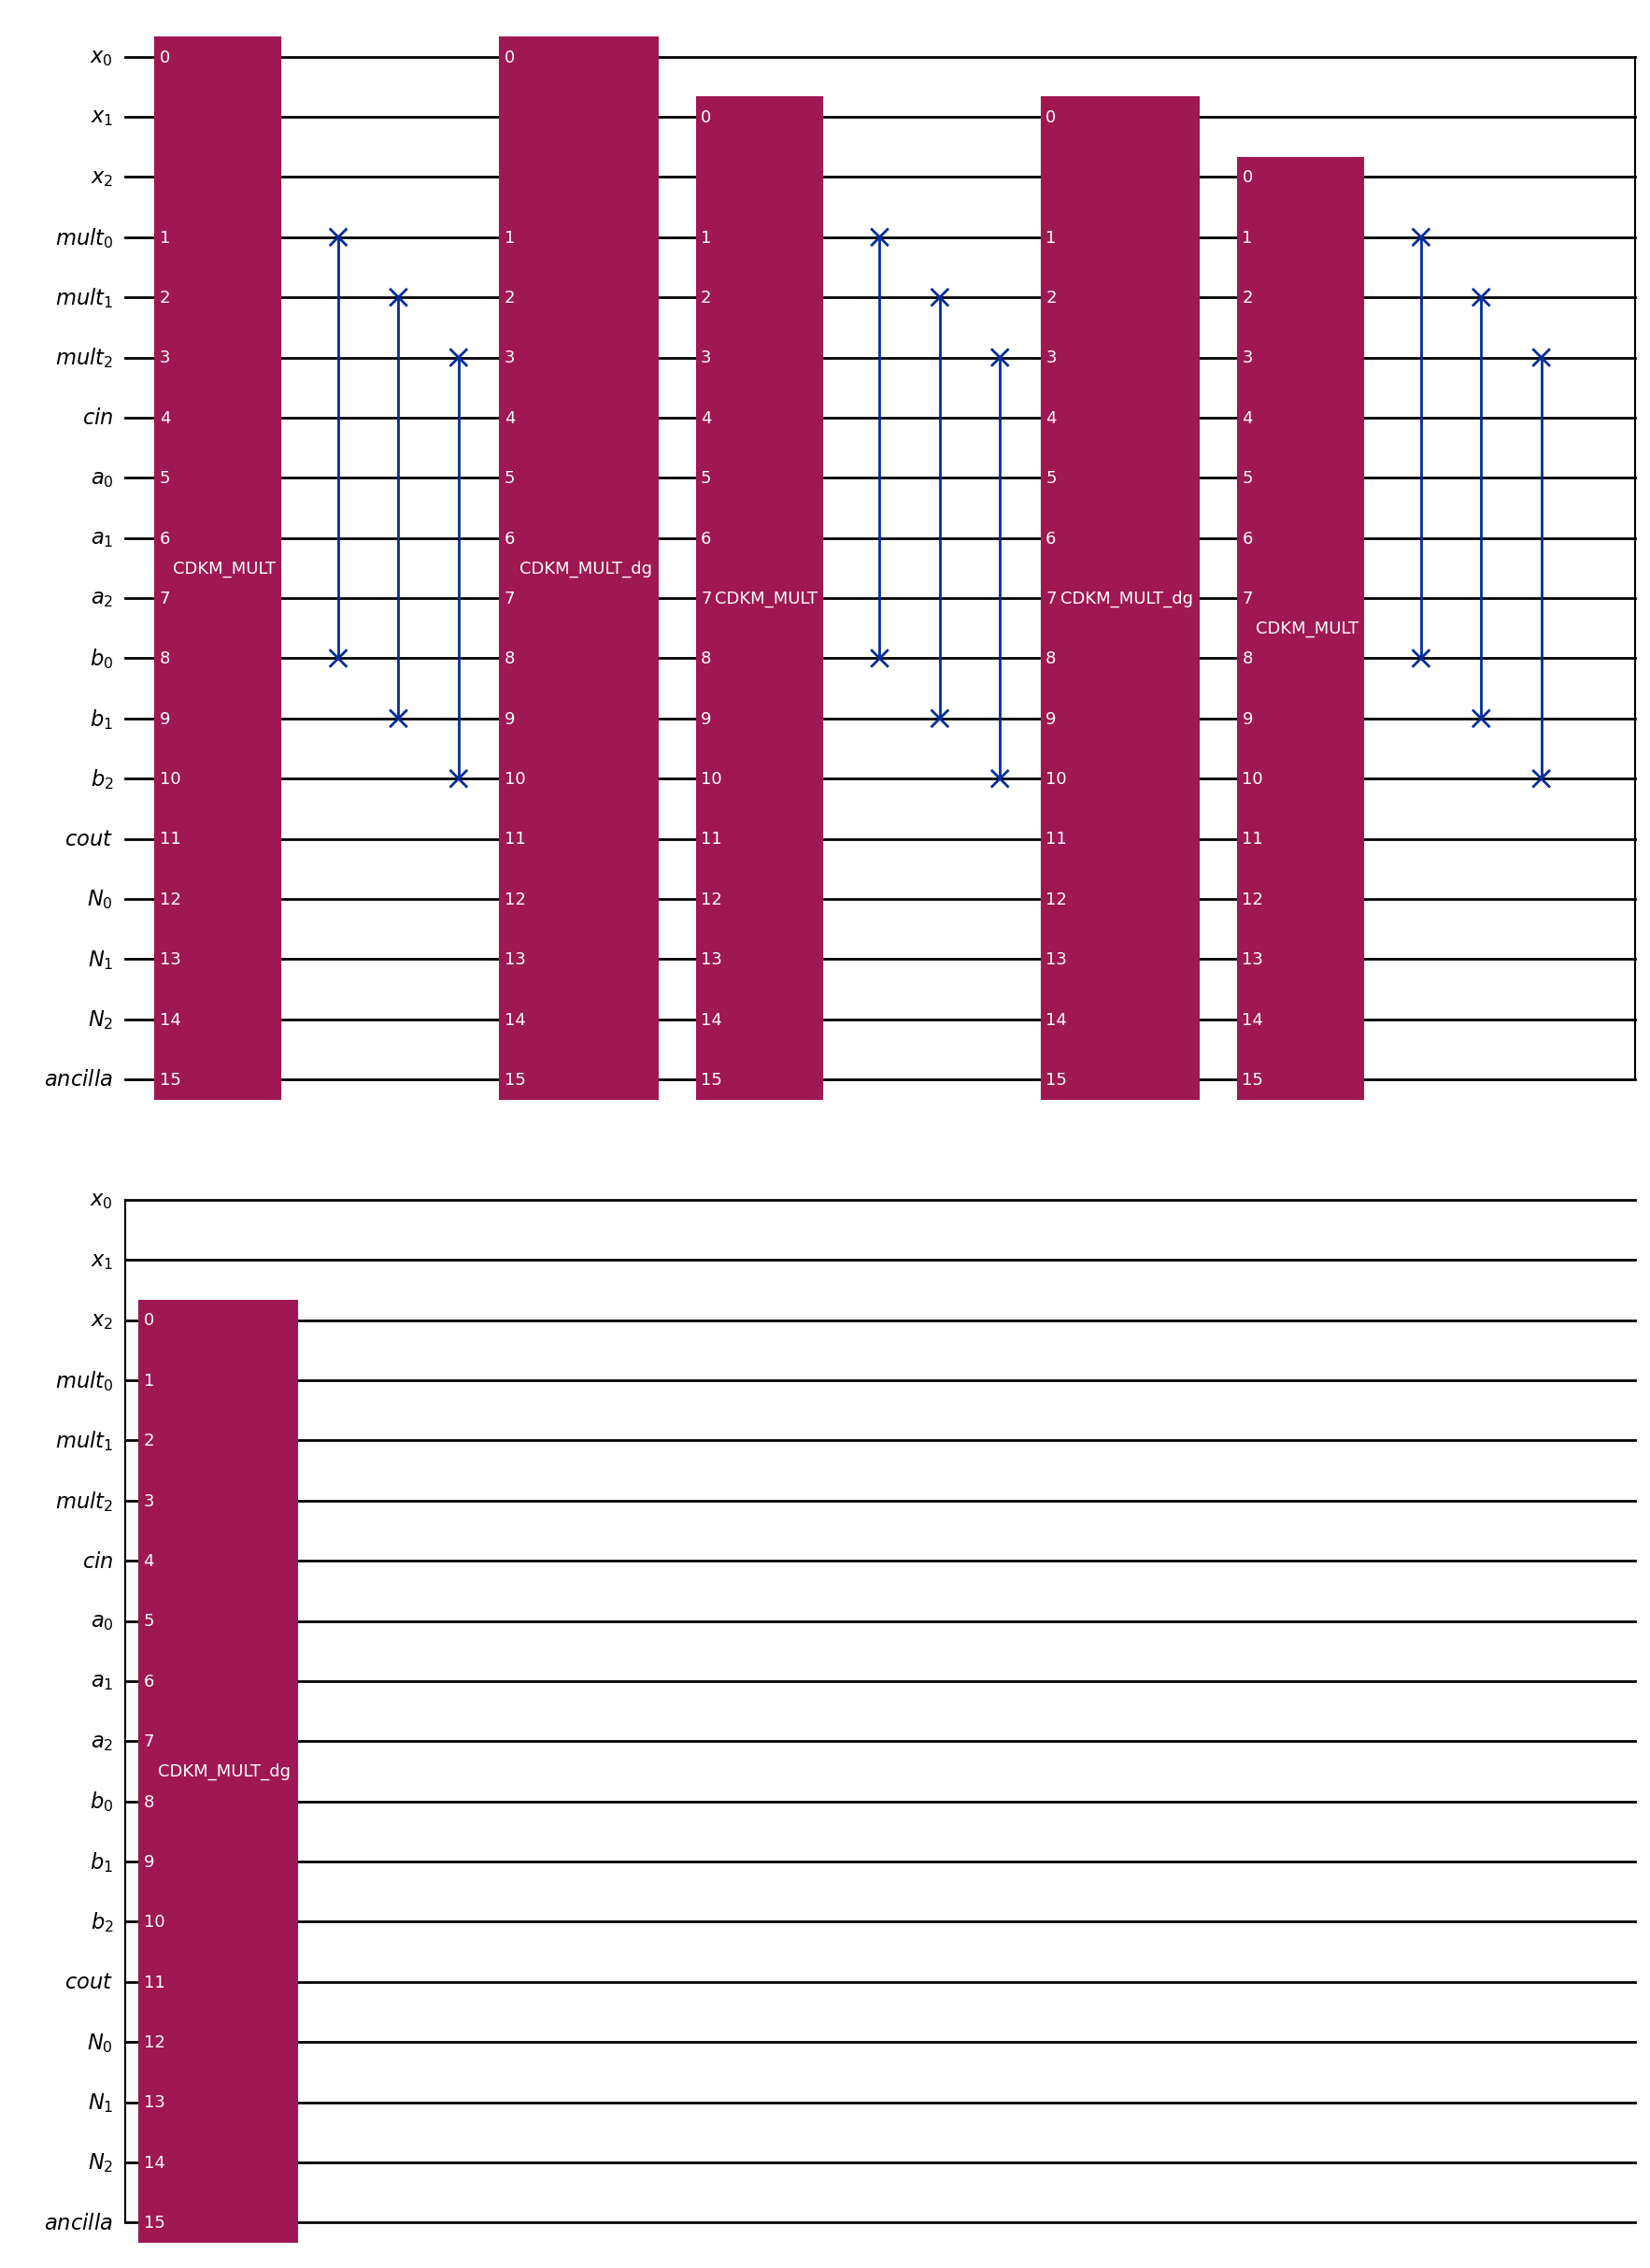

RESULT FOR CIRCUIT ABOVE

Value of a: 3
Value of b: 9
Value of N: 5

Bit length n = 3
Qubits Required for CDKM Modular Exponentiator: 5*n + 3 = 18 

Expected result:  4
Calculated result: 4
Correct? True 

RESULT

Value of a: 3
Value of b: 9
Value of N: 7

Bit length n = 3
Qubits Required for CDKM Modular Exponentiator: 5*n + 3 = 18 

Expected result:  4
Calculated result: 4
Correct? True 



In [ ]:

def CDKM_MODEXP(a, N, showcircuit = False):
    """Creates a Modular Exponentiation Gate based on the CDKM Modular Multiplier"""

    N_binary = np.binary_repr(N)
    n = len(N_binary)

    # qubits_needed = ( (3*n + 3) + n ) + n # CDKM_MMODMULT registers, minus the generic control, plus x (which becomes the control)

    # qc = QuantumCircuit(qubits_needed, name="CDKM_EXP")

    # Create the circuit
    controls = QuantumRegister(n, "x")
    x_register = QuantumRegister(n, "mult")
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    cout = QuantumRegister(1, "cout")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla")

    # The number of classical bits needed is size of b
    # classical_bits = ClassicalRegister(n)

    qc = QuantumCircuit(controls, x_register, cin, a_register, b_register, cout, N_register, ancilla, name ="CDKM_EXP")

    # Here we identify where each part of the circuit begins
    # start_of_x = 0
    # end_of_x = n - 1

    start_of_x_for_mult = n
    # end_of_x_for_mult = 2*n -1

    # pseudo_cin = 2*n

    # start_of_pseudo_a = 2*n + 1
    # end_of_pseudo_a = 3*n

    start_of_pseudo_b = 3*n + 1
    # end_of_pseudo_b = 4*n

    # pseudo_cout = 4*n + 1

    # start_of_N_for_mult = 4*n + 2
    # end_of_N_for_mult = 5*n + 1

    helper = 5*n + 2


    # Calculating the constants to pass to the circuit
    capital_As = []
    for i in range(n):
        Ai = int(np.mod(a**2**i, N))
        capital_As.append(Ai)


    # Implementing the CDKM Modular Multiplier gates (and corresponding inverses) created previously
    modmult_qubits = [q for q in range(start_of_x_for_mult, helper + 1)]
    for i in range(n):

        # Control plus qubits used by the gate
        qargs = [i] + modmult_qubits

        # Constant to pass
        A_i = capital_As[i]

        # Add the circuit
        CMODMULT = CDKM_MODMULT(A_i, N)
        qc.append(CMODMULT, qargs)

        # Swapping registers
        for k in range(n):
            qc.swap(start_of_x_for_mult + k, start_of_pseudo_b + k)

        # Implement iverse to reset accumulation register
        # Observe we use the inverse gate and also pass the inverse of A_i mod N
        CMODMULT_inverse = CDKM_MODMULT(pow(A_i, -1, N), N).inverse()

        qc.append(CMODMULT_inverse, qargs)

    # Pass the circuit to instruction for later use as a gate
    modexp_circuit = qc.to_instruction()

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return modexp_circuit


def create_cdkm_modexp_circuit(a, x, N, showcircuit = False):
    """Prepares the circuit and finds the result of a^x mod N using the CDKM Modular Exponentiator"""

    # Choose backend
    sim = AerSimulator()

    # For checking purposes
    x_binary = np.binary_repr(x)
    N_binary = np.binary_repr(N)
    length_of_x = len(x_binary)
    length_of_N = len(N_binary)

    n = length_of_N 

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_x < length_of_N):
        padding = "0" * (length_of_N - length_of_x)
        x_binary = padding + x_binary

    length_of_x = len(x_binary)

    # Create the circuit
    qubits_needed = ( (3*n + 3) + n ) + n # CDKM_MMODMULT registers, minus the generic control, plus x (which becomes the control)
    classical_bits_needed = n
    qc = QuantumCircuit(qubits_needed, classical_bits_needed)

    # Here we identify where the result is stored
    start_of_x_for_mult = n
    end_of_x_for_mult = 2*n - 1


    # Constructing the initial state
    initial_x_for_mult_register = "0" * (n - 1) + "1" # initialized to ...0001
    initial_pseudo_a_register = "0" * n
    initial_pseudo_b_register = "0" * n

    initial_state = "0" + N_binary + "0" + initial_pseudo_b_register + initial_pseudo_a_register + "0" + initial_x_for_mult_register + x_binary

    qc.initialize(initial_state, qc.qubits)

    # Use the gate we constructed above
    my_cdkm_modexp = CDKM_MODEXP(a, N, showcircuit)
    qc = qc.compose(my_cdkm_modexp, qc.qubits)

    # Measure the regester where the result is stored
    binary_bits = list(range(start_of_x_for_mult, end_of_x_for_mult + 1))
    classical_bits = list(range(classical_bits_needed))
    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # Show the results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of b:", b)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for CDKM Modular Exponentiator: 5*n + 3 = {qubits_needed} \n")

        expected = np.mod(a**x, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")

# Use the circuit
a = 3
x = 2
N = 5

create_cdkm_modexp_circuit(a, x, N, True)

create_cdkm_modexp_circuit(3, 4, 7)